# Proyecto Integrador de Ciencia de Datos
## Fase 3, actividad 5: Perceptrón multicapa (MLP) en PyTorch

**Universidad de La Salle**, Maestría en Inteligencia Artificial
**Asignatura:** Ciencia de Datos (2026-2). **Docente:** Fabián Camilo Castro Riveros
**Estudiante:** Martín Gracia Socha (trabajo individual)
**Conjunto de datos:** METABRIC

### Contenido
1. Configuración
2. Datos y preprocesamiento sin fuga
3. Arquitectura del MLP
4. Entrenamiento con parada temprana
5. Selección de hiperparámetros con validación cruzada
6. Modelo final: curvas de pérdida y desempeño en validación
7. Conclusiones

**Tarea:** clasificar el subtipo PAM50 (6 clases), la misma tarea de los clasificadores del cuaderno 04, para poder compararlos en la actividad 6.

## 1. Configuración

In [1]:
import sys
import json
import time
import warnings
from pathlib import Path

# --- Entorno: en Google Colab se clona el repositorio y se instalan dependencias faltantes ---
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/MartinGia/metabric-proyecto-integrador.git"
if IN_COLAB:
    # En Colab se clona el repositorio (datos, código y modelos) y se instalan las librerías que Colab no trae.
    import os, subprocess, importlib.util
    repo_dir = Path("/content/metabric-proyecto-integrador")
    if not (repo_dir / "src" / "config.py").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(repo_dir)], check=True)
    os.chdir(repo_dir / "notebooks")
    for pkg, module in [("imbalanced-learn", "imblearn"), ("xgboost", "xgboost"), ("shap", "shap")]:
        if importlib.util.find_spec(module) is None:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

def find_project_root():
    for c in [Path.cwd(), *Path.cwd().parents]:
        if (c / "src" / "config.py").exists():
            return c
    raise FileNotFoundError("No se encontró la carpeta del proyecto (debe contener src/config.py). "
                            "Abra el notebook desde la carpeta notebooks/ del repositorio.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

import copy
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix

# --- Localización de la raíz del proyecto (carpeta que contiene src/config.py) ---
ROOT = find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import config
from src.preprocessing import build_preprocessor, all_columns
from src.modeling import load_processed, task_data, classification_metrics, CLASS_ORDER

config.ensure_dirs()
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
SEED = config.RANDOM_STATE
np.random.seed(SEED)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

def savefig(name):
    plt.savefig(config.FIGURES_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

print("Carpeta del proyecto:", ROOT.name)

Carpeta del proyecto: Proyecto Integrador


In [2]:
torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True, warn_only=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| dispositivo:", DEVICE)

PyTorch 2.5.1 | dispositivo: cpu


## 2. Datos y preprocesamiento sin fuga
Se usa el mismo `ColumnTransformer` de la actividad 3, ajustado solo con entrenamiento. Para no gastar el conjunto de validación en la parada temprana, se separa un 15 % estratificado **de entrenamiento** como conjunto de parada temprana (*early stopping*). Así, la validación sigue siendo independiente y comparable con los modelos de scikit-learn.

In [3]:
df, FS = load_processed()
clf_df, y_clf = task_data(df, "classification")
cols = all_columns(FS["classification"])
tr, va = clf_df[clf_df.split == "train"], clf_df[clf_df.split == "val"]

le = LabelEncoder().fit(CLASS_ORDER)
y_tr, y_va = le.transform(tr[y_clf]), le.transform(va[y_clf])
N_CLASSES = len(le.classes_)
print("Clases (orden interno):", [str(c) for c in le.classes_])
print(f"Entrenamiento: {len(tr)} | Validación: {len(va)} | Predictores originales: {len(cols)}")

Clases (orden interno): ['Basal', 'Her2', 'LumA', 'LumB', 'Normal', 'claudin-low']
Entrenamiento: 1328 | Validación: 284 | Predictores originales: 576


## 3. Arquitectura del MLP
Red *feed-forward* con dos capas ocultas:

`entrada (≈ 593) → Lineal → BatchNorm → ReLU → Dropout → Lineal → BatchNorm → ReLU → Dropout → Lineal (6 logits)`

* **Función de pérdida:** entropía cruzada **ponderada por clase** (pesos inversos a la frecuencia), coherente con `class_weight="balanced"` de los otros modelos.
* **Regularización:** *dropout*, *weight decay* (L2 en AdamW) y parada temprana, porque la actividad 4 mostró que el problema es de alta varianza (casi 600 predictores para unas 1.300 pacientes).
* **Optimizador:** AdamW con tasa de aprendizaje 1e-3 y lotes de 64 pacientes.

In [4]:
class MLP(nn.Module):
    def __init__(self, n_in, hidden=(256, 64), dropout=0.5, n_out=6):
        super().__init__()
        layers, prev = [], n_in
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, n_out))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def to_tensor(X, y=None):
    X = torch.tensor(np.asarray(X, dtype=np.float32))
    return X if y is None else (X, torch.tensor(np.asarray(y), dtype=torch.long))


def train_mlp(X_fit, y_fit, X_es, y_es, hidden=(256, 64), dropout=0.5, weight_decay=1e-3, lr=1e-3,
              max_epochs=300, patience=25, batch_size=64, seed=SEED):
    """Entrena con parada temprana sobre (X_es, y_es). Devuelve el modelo con los mejores pesos y el historial."""
    torch.manual_seed(seed)
    model = MLP(X_fit.shape[1], hidden, dropout, N_CLASSES).to(DEVICE)
    w = compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=y_fit)
    loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32, device=DEVICE))
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    g = torch.Generator().manual_seed(seed)
    loader = DataLoader(TensorDataset(*to_tensor(X_fit, y_fit)), batch_size=batch_size, shuffle=True, generator=g)
    Xe, ye = [t.to(DEVICE) for t in to_tensor(X_es, y_es)]
    hist, best, best_loss, wait = [], None, np.inf, 0
    for epoch in range(1, max_epochs + 1):
        model.train()
        tot, n = 0.0, 0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
            tot += loss.item() * len(xb)
            n += len(xb)
        model.eval()
        with torch.no_grad():
            logits = model(Xe)
            es_loss = loss_fn(logits, ye).item()
            es_f1 = classification_metrics(y_es, logits.argmax(1).cpu().numpy())["F1_macro"]
        hist.append({"epoch": epoch, "train_loss": tot / n, "es_loss": es_loss, "es_f1": es_f1})
        if es_loss < best_loss - 1e-4:
            best_loss, best, wait = es_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best)
    return model, pd.DataFrame(hist)


def predict_proba(model, X):
    model.eval()
    with torch.no_grad():
        return torch.softmax(model(to_tensor(X).to(DEVICE)), dim=1).cpu().numpy()

## 4. Selección de hiperparámetros con validación cruzada
Se comparan 8 configuraciones (tamaño de las capas ocultas, *dropout* y *weight decay*) con **validación cruzada estratificada de 5 pliegues sobre entrenamiento**. En cada pliegue, el preprocesador se ajusta solo con la parte de entrenamiento del pliegue, y de ella se separa un 15 % para la parada temprana.

In [5]:
grid = [{"hidden": h, "dropout": d, "weight_decay": wd}
        for h in [(256, 64), (128,)] for d in [0.3, 0.5] for wd in [1e-4, 1e-2]]
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
cv_rows = []
t0 = time.time()
for cfg in grid:
    f1s, epochs = [], []
    for k, (i_fit, i_ev) in enumerate(skf.split(tr, y_tr)):
        i_fit2, i_es = train_test_split(i_fit, test_size=0.15, stratify=y_tr[i_fit], random_state=SEED)
        pre = build_preprocessor(FS["classification"]).fit(tr.iloc[i_fit2][cols])
        model, h = train_mlp(pre.transform(tr.iloc[i_fit2][cols]), y_tr[i_fit2],
                             pre.transform(tr.iloc[i_es][cols]), y_tr[i_es], **cfg, seed=SEED + k)
        pred = predict_proba(model, pre.transform(tr.iloc[i_ev][cols])).argmax(1)
        f1s.append(classification_metrics(y_tr[i_ev], pred)["F1_macro"])
        epochs.append(int(h.loc[h.es_loss.idxmin(), "epoch"]))
    cv_rows.append({"capas ocultas": str(cfg["hidden"]), "dropout": cfg["dropout"], "weight_decay": f'{cfg["weight_decay"]:.0e}',
                    "F1 macro CV": np.mean(f1s), "desv.": np.std(f1s), "épocas (media)": np.mean(epochs)})
cv_table = pd.DataFrame(cv_rows).sort_values("F1 macro CV", ascending=False).reset_index(drop=True)
print(f"Tiempo total: {time.time() - t0:.0f} s")
cv_table

Tiempo total: 51 s


,capas ocultas,dropout,weight_decay,F1 macro CV,desv.,épocas (media)
0,"(256, 64)",0.300,1e-04,0.716,0.029,7.000
1,"(256, 64)",0.300,1e-02,0.712,0.030,7.000
2,"(128,)",0.500,1e-02,0.709,0.019,7.000
3,"(256, 64)",0.500,1e-04,0.709,0.020,9.800
4,"(128,)",0.500,1e-04,0.708,0.018,7.000
5,"(256, 64)",0.500,1e-02,0.708,0.027,9.400
6,"(128,)",0.300,1e-04,0.702,0.021,5.600
7,"(128,)",0.300,1e-02,0.702,0.021,5.600


## 5. Modelo final: curvas de pérdida y desempeño en validación

Configuración seleccionada: {'hidden': (256, 64), 'dropout': 0.3, 'weight_decay': 0.0001}


Épocas entrenadas: 32 | mejor época (mínima pérdida de parada temprana): 7
Parámetros entrenables: 169,286


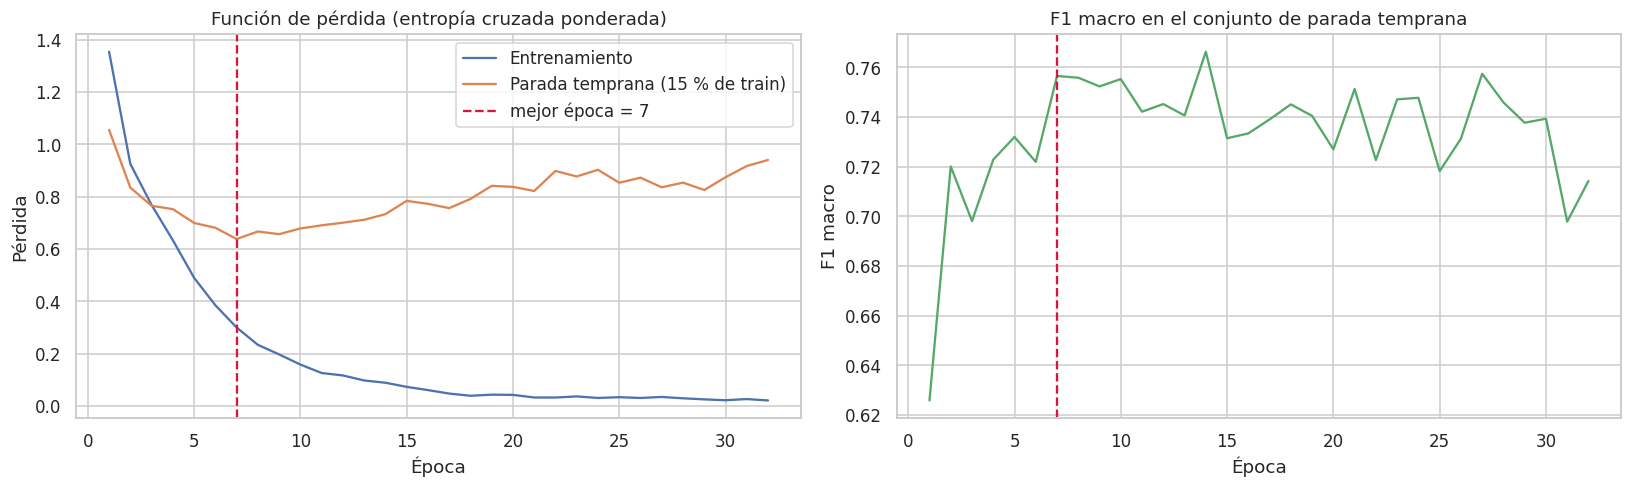

In [6]:
best = cv_table.iloc[0]
best_cfg = {"hidden": eval(best["capas ocultas"]), "dropout": float(best["dropout"]), "weight_decay": float(best["weight_decay"])}
print("Configuración seleccionada:", best_cfg)

i_fit, i_es = train_test_split(np.arange(len(tr)), test_size=0.15, stratify=y_tr, random_state=SEED)
pre = build_preprocessor(FS["classification"]).fit(tr.iloc[i_fit][cols])
X_fit, X_es, X_va = (pre.transform(tr.iloc[i_fit][cols]), pre.transform(tr.iloc[i_es][cols]), pre.transform(va[cols]))
model, hist = train_mlp(X_fit, y_tr[i_fit], X_es, y_tr[i_es], **best_cfg)
best_epoch = int(hist.loc[hist.es_loss.idxmin(), "epoch"])
print(f"Épocas entrenadas: {len(hist)} | mejor época (mínima pérdida de parada temprana): {best_epoch}")
print(f"Parámetros entrenables: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
axes[0].plot(hist.epoch, hist.train_loss, label="Entrenamiento")
axes[0].plot(hist.epoch, hist.es_loss, label="Parada temprana (15 % de train)")
axes[0].axvline(best_epoch, color="crimson", ls="--", label=f"mejor época = {best_epoch}")
axes[0].set(title="Función de pérdida (entropía cruzada ponderada)", xlabel="Época", ylabel="Pérdida")
axes[0].legend()
axes[1].plot(hist.epoch, hist.es_f1, color="#55A868")
axes[1].axvline(best_epoch, color="crimson", ls="--")
axes[1].set(title="F1 macro en el conjunto de parada temprana", xlabel="Época", ylabel="F1 macro")
plt.tight_layout()
savefig("26_mlp_curvas_perdida")
plt.show()

,Accuracy,Balanced_Accuracy,Precision_macro,Recall_macro,F1_macro,AUC_ROC_ovr
MLP entrenamiento,0.932,0.949,0.921,0.949,0.933,0.997
MLP validación,0.771,0.767,0.757,0.767,0.759,0.950
MLP CV (selección),NaN,NaN,NaN,NaN,0.716,NaN
Modelo base (logística) validación,NaN,NaN,NaN,NaN,0.755,0.959
Modelo base (logística) CV,NaN,NaN,NaN,NaN,0.698,NaN


Brecha F1 entrenamiento - CV: 0.217 (modelo base: 0,302)


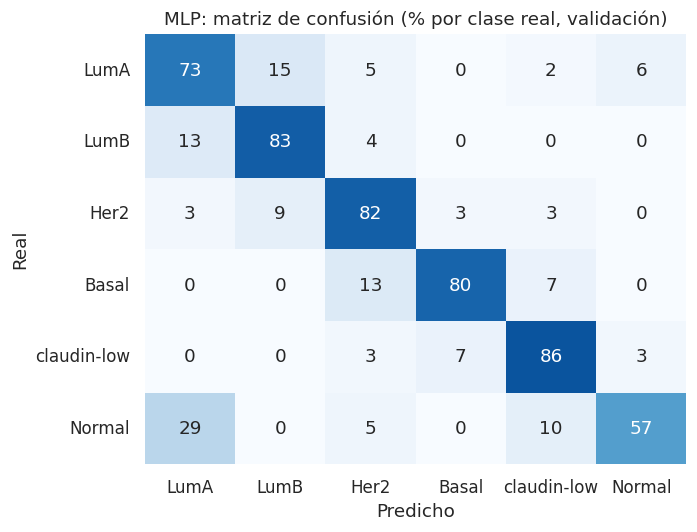

In [7]:
proba_tr = predict_proba(model, np.vstack([X_fit, X_es]))
y_tr_all = np.concatenate([y_tr[i_fit], y_tr[i_es]])
proba_va = predict_proba(model, X_va)
m_tr = classification_metrics(y_tr_all, proba_tr.argmax(1), proba_tr, np.arange(N_CLASSES))
m_va = classification_metrics(y_va, proba_va.argmax(1), proba_va, np.arange(N_CLASSES))
baseline = json.load(open(config.METRICS_DIR / "baseline_thresholds.json", encoding="utf-8"))["classification"]
res = pd.DataFrame({"MLP entrenamiento": m_tr, "MLP validación": m_va}).T
res.loc["MLP CV (selección)", "F1_macro"] = best["F1 macro CV"]
res.loc["Modelo base (logística) validación", ["F1_macro", "AUC_ROC_ovr"]] = [baseline["F1_macro_val"], baseline["AUC_val"]]
res.loc["Modelo base (logística) CV", "F1_macro"] = baseline["F1_macro_cv"]
display(res)
print(f"Brecha F1 entrenamiento - CV: {m_tr['F1_macro'] - best['F1 macro CV']:.3f} (modelo base: 0,302)")

cm = confusion_matrix(y_va, proba_va.argmax(1), labels=le.transform(CLASS_ORDER), normalize="true")
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(cm * 100, annot=True, fmt=".0f", cmap="Blues", xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER,
            ax=ax, cbar=False, vmin=0, vmax=100)
ax.set(title="MLP: matriz de confusión (% por clase real, validación)", xlabel="Predicho", ylabel="Real")
plt.tight_layout()
savefig("27_mlp_confusion")
plt.show()

In [8]:
# Se guardan los pesos y la configuración en formatos independientes de la versión de scikit-learn.
# El preprocesador se reconstruye de forma determinística (mismas filas de ajuste: train sin el 15 % de parada temprana).
import sklearn
torch.save(model.state_dict(), config.MODELS_DIR / "mlp_pam50.pt")
meta = {"hidden": list(best_cfg["hidden"]), "dropout": float(best_cfg["dropout"]),
        "weight_decay": float(best_cfg["weight_decay"]), "n_in": int(X_fit.shape[1]), "classes": [str(c) for c in le.classes_],
        "best_epoch": best_epoch, "early_stopping_patient_ids": tr.iloc[i_es]["patient_id"].tolist(),
        "torch": torch.__version__, "sklearn": sklearn.__version__}
with open(config.MODELS_DIR / "mlp_pam50_config.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=1)
cv_table.to_csv(config.METRICS_DIR / "act5_mlp_cv.csv", index=False)
hist.to_csv(config.METRICS_DIR / "act5_mlp_historial.csv", index=False)
res.to_csv(config.METRICS_DIR / "act5_mlp_resultados.csv", encoding="utf-8-sig")
print("Guardado: models/mlp_pam50.pt, models/mlp_pam50_config.json y métricas en reports/metrics/")

Guardado: models/mlp_pam50.pt, models/mlp_pam50_config.json y métricas en reports/metrics/


## 7. Conclusiones

1. **Selección.** Las 8 configuraciones quedan en un rango estrecho de F1 macro en CV (0,702 a 0,716), así que la arquitectura importa poco frente al tamaño de la muestra. La mejor configuración tiene dos capas ocultas (256 y 64 neuronas), *dropout* de 0,3 y *weight decay* de 1e-4: F1 macro = 0,716 ± 0,029 en CV.
2. **Curvas de pérdida.** La pérdida de entrenamiento baja de forma continua, mientras que la del conjunto de parada temprana llega a su mínimo en muy pocas épocas y luego sube. Es la señal típica de sobreajuste de una red con unos 169.000 parámetros entrenada con poco más de 1.100 pacientes. La parada temprana restaura los pesos de la mejor época y es la regularización más importante de este modelo.
3. **Desempeño en validación.** F1 macro = 0,759, exactitud = 0,771 y AUC-ROC = 0,950. Supera al modelo base en CV (0,716 frente a 0,698) y reduce la brecha de sobreajuste (0,22 frente a 0,30), pero queda por debajo de XGBoost (0,746 en CV) y de la logística regularizada (0,736) del cuaderno 04. Con datos tabulares de este tamaño, los modelos lineales regularizados y los ensambles de árboles suelen igualar o superar a las redes densas.
4. **Para la actividad 6.** El MLP entra en la comparación final sobre el conjunto de prueba junto con los modelos del cuaderno 04. Los pesos están en `models/mlp_pam50.pt` y la configuración en `models/mlp_pam50_config.json`.